# Turbulent pipe flow and the Fanning friction factor

Laminar pipe flow of a Herschel–Bulkley (HB) fluid is solved exactly (notebook 05). Many industrial flows — drilling-fluid circulation, slurry pipelines, mine tailings — run fast enough to be transitional or turbulent, and there no exact solution exists. Engineers then use the framework built by Metzner and Reed (1955) and Dodge and Metzner (1959): describe the laminar pipe-flow curve locally by a power law with index $n'$ and consistency $K'$, form a generalized Reynolds number, and read the Fanning friction factor from a laminar line or a turbulent correlation. This notebook computes $n'$ and $K'$ from the HB law, shows that the laminar line $f_F=16/\mathrm{Re_{MR}}$ is exact for an HB fluid, reproduces Supplementary Fig. S7, and works through laminar and turbulent pressure-drop calculations. It also explains why the transition band drawn in Fig. S7 is only illustrative.

## Where this is in the review

* **Sec. IV C**, **Eq. (9)** and **Table IV** — the Metzner–Reed Reynolds number $\mathrm{Re_{MR}}$, the local index $n'$ and consistency $K'$, the power-law values of $n'$ and $K'$, and the reduction $\mathrm{Re_{MR}}=8\rho U^2/\sigma_w$, $f_F=16/\mathrm{Re_{MR}}$ for any laminar flow curve.
* **Sec. VII A** — the exact laminar solution, Eq. (19), and the statement that transitional and turbulent HB pipe flow is not yet captured consistently (Yusufi, Kapelan and Mehta, 2025; Supplementary Note S12 B). **Table III** — the engineering milestones of Metzner and Reed (1955), Dodge and Metzner (1959) and Hanks (1963).
* **Supplementary Note S9 E** — Fanning and Darcy factors, $\Delta p=4\sigma_wL/D$, pumping power $Q\Delta p$, and the caveat that $\mathrm{Re_{MR}}$ organizes turbulent data but is not an exact turbulent solution.
* **Supplementary Note S12 A**, **Fig. S7** — laminar line, Dodge–Metzner turbulent curves and an *illustrative* transition band; **Note S12 C** — experiments resolve regimes, not one universal critical number; **Note S12 E** — wall scaling, Eq. (S31), and the calibration domain of empirical correlations.
* **Supplementary Note S15 B, Example 1** — the slurry-pipeline worked example reproduced in Sec. 7.
* **Sec. X A**, **Table XIII** — pressure loss in drilling and pipelines.
* Script `scripts/figS7_friction_factor.py`; plotted values `data/figure_data/figS7_friction_factor.csv`; exact laminar model `scripts/hb_prediction.py`.

## Learning objectives

1. Define the nominal wall shear rate $8U/D$ and the local Metzner–Reed parameters $n'$ and $K'$, and compute them for an HB fluid.
2. Show that $\mathrm{Re_{MR}}=8\rho U^2/\sigma_w$ and $f_F=16/\mathrm{Re_{MR}}$ hold exactly in laminar HB flow.
3. Evaluate the Dodge–Metzner correlation and reproduce Fig. S7.
4. Compute a laminar and a turbulent pressure drop and the pumping power, and avoid the Fanning/Darcy factor-of-four trap.
5. Explain why no single critical Reynolds number marks the transition for HB fluids.

## 1. Theory

### 1.1 The laminar pipe-flow curve and its local power-law description

In fully developed pipe flow the wall shear stress follows from the pressure drop alone, $\sigma_w=D\,\Delta p/(4L)$ (momentum balance, Sec. VII A). The **nominal wall shear rate** $8U/D$, with $U$ the mean velocity, follows from the flow rate alone. For a Newtonian liquid $8U/D$ is the true wall shear rate. For any fluid in steady laminar no-slip flow, $\sigma_w$ is a unique function of $8U/D$ — the pipe-flow curve — because $Q=\pi\int_0^R\dot\gamma\,r^2\mathrm{d}r$ depends only on the wall stress once the flow curve $\dot\gamma(\sigma)$ is fixed.

Metzner and Reed (1955) described this curve locally by a power law (Sec. IV C):

$$
n'=\frac{\mathrm{d}\ln\sigma_w}{\mathrm{d}\ln(8U/D)},\qquad K'=\frac{\sigma_w}{(8U/D)^{n'}} .
$$

For a power-law fluid $n'=n$ and $K'=K[(3n+1)/(4n)]^n$. For an HB fluid $n'$ varies along the curve: near the threshold, $\sigma_w$ hardly changes while $U$ grows from zero, so $n'\to0$; far above it, $n'\to n$.

*A useful identity (classical, not printed in the review).* Differentiating $Q$ with respect to $\sigma_w$ gives the Rabinowitsch–Mooney relation between the true wall shear rate $\dot\gamma_w$ and the nominal one (Rabinowitsch, 1929; Mooney, 1931):

$$
\dot\gamma_w=\frac{3n'+1}{4n'}\,\frac{8U}{D}\qquad\Longleftrightarrow\qquad n'=\left[\frac{4\dot\gamma_w}{8U/D}-3\right]^{-1},
$$

so for an HB fluid, with $\dot\gamma_w=[(\sigma_w-\sigma_y)/K]^{1/n}$ and $U$ from Eq. (19), $n'$ is available in closed form. We check it below against a numerical derivative.

### 1.2 The Metzner–Reed Reynolds number and the laminar friction factor

With $\rho$ the density and $D$ the diameter, Eq. (9) of the review reads

$$
\mathrm{Re_{MR}}=\frac{\rho U^{2-n'}D^{n'}}{K'\,8^{\,n'-1}} .
$$

Substituting $K'=\sigma_w/(8U/D)^{n'}$ gives, for **any** laminar flow curve and therefore exactly for HB,

$$
\mathrm{Re_{MR}}=\frac{8\rho U^2}{\sigma_w},\qquad
f_F\equiv\frac{\sigma_w}{\tfrac12\rho U^2}=\frac{16}{\mathrm{Re_{MR}}} .
$$

The pressure drop over a length $L$ is $\Delta p=4\sigma_wL/D=2f_F\rho U^2L/D$, and the pumping power is $Q\,\Delta p$. The Darcy friction factor is $f_D=4f_F$; mixing the two conventions causes a factor-of-four error even when the rheology is right (Supplementary Note S9 E).

### 1.3 The Dodge–Metzner turbulent correlation

For turbulent flow in smooth pipes, Dodge and Metzner (1959) correlated their data by

$$
\frac{1}{\sqrt{f_F}}=\frac{4}{n'^{\,0.75}}\log_{10}\!\left(\mathrm{Re_{MR}}\,f_F^{\,1-n'/2}\right)-\frac{0.4}{n'^{\,1.2}},
$$

which is implicit in $f_F$. For $n'=1$ it is the Newtonian smooth-pipe law $1/\sqrt{f_F}=4\log_{10}(\mathrm{Re}\sqrt{f_F})-0.4$. In turbulent flow, $n'$ and $K'$ are taken from the **laminar** pipe-flow curve (they describe the material, not the turbulence), evaluated at the wall shear stress of the turbulent flow; this is how the correlation is applied in Sec. 8. The review stresses that in this use $\mathrm{Re_{MR}}$ "organizes data but is not an exact turbulent solution" (Note S9 E), and that an empirical correlation is an appropriate baseline only when its calibration domain matches the application (Note S12 E); consult Dodge and Metzner (1959) for the range of $n'$ and $\mathrm{Re_{MR}}$ behind the correlation.

### 1.4 Transition

There is no exact transition criterion. Linear stability, energy stability and observed transition are different things; pipe-flow experiments with yield-stress fluids show a broad, intermittent transition with plug break-up and non-axisymmetric structures (Escudier and Presti, 1996; Peixinho et al., 2005; Güzel et al., 2009; Charles et al., 2024). The review therefore recommends **no single critical $\mathrm{Re_{MR}}$ for all HB fluids** (Note S12 A). The shaded band $2100\le\mathrm{Re_{MR}}\le3000$ in Fig. S7 is **only an illustrative Newtonian transition band**; HB transition is material- and disturbance-dependent. Criteria that include the yield stress, such as that of Hanks (1963), exist but are outside this notebook.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.optimize import brentq
import hb_prediction            # exact laminar SI pipe model: pipe_flux(sigma_w, R, sigma_y, K, n), pressure_gradient(Q, R, ...)

data folder found: True


## 3. The local parameters $n'$ and $K'$ of an HB fluid

We code the laminar pipe-flow curve with `hb_prediction.pipe_flux` and compute $n'$ two ways: from the Rabinowitsch–Mooney closed form, and by numerically differentiating $\ln\sigma_w$ with respect to $\ln(8U/D)$.

In [2]:
def nominal_rate(tw, R, ty, K, n):
    """8U/D = 4Q/(pi R^3) for the exact laminar HB flow at wall stress tw."""
    return 4 * float(hb_prediction.pipe_flux(tw, R, ty, K, n)) / (np.pi * R**3)

def n_prime(tw, R, ty, K, n):
    """Local Metzner-Reed index from the Rabinowitsch-Mooney relation."""
    gw = ((tw - ty) / K) ** (1 / n)              # true wall shear rate from the HB law
    return 1.0 / (4 * gw / nominal_rate(tw, R, ty, K, n) - 3)

def K_prime(tw, R, ty, K, n):
    return tw / nominal_rate(tw, R, ty, K, n) ** n_prime(tw, R, ty, K, n)

def n_prime_numeric(tw, R, ty, K, n, h=1e-5):
    """Central difference of ln(sigma_w) with respect to ln(8U/D)."""
    lo, hi = tw * (1 - h), tw * (1 + h)
    return (np.log(hi) - np.log(lo)) / (np.log(nominal_rate(hi, R, ty, K, n)) - np.log(nominal_rate(lo, R, ty, K, n)))

worst = 0.0
for n in [0.4, 0.7, 1.0]:
    for ratio in [1.05, 2.0, 10.0]:
        worst = max(worst, abs(n_prime(ratio * 5.0, 0.05, 5.0, 0.5, n) / n_prime_numeric(ratio * 5.0, 0.05, 5.0, 0.5, n) - 1))
print(f"n' closed form vs numerical derivative: largest relative difference = {worst:.1e}")
assert worst < 1e-7

# Power-law limit (sigma_y = 0): n' = n and K' = K [(3n+1)/(4n)]^n  (Sec. IV C)
for n in [0.4, 0.7, 1.0]:
    assert np.isclose(n_prime(30.0, 0.05, 0.0, 0.5, n), n, rtol=1e-10)
    assert np.isclose(K_prime(30.0, 0.05, 0.0, 0.5, n), 0.5 * ((3 * n + 1) / (4 * n)) ** n, rtol=1e-10)
print("Power-law limit reproduced: n' = n, K' = K[(3n+1)/(4n)]^n.")

n' closed form vs numerical derivative: largest relative difference = 1.5e-08
Power-law limit reproduced: n' = n, K' = K[(3n+1)/(4n)]^n.


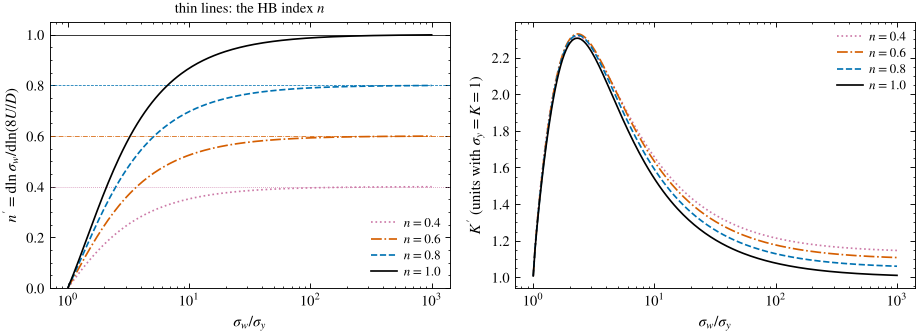

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
ratio = np.logspace(np.log10(1.001), 3, 200)                   # sigma_w / sigma_y
for n, col, ls in zip([0.4, 0.6, 0.8, 1.0], [C["purple"], C["red"], C["blue"], C["black"]], [":", "-.", "--", "-"]):
    npr = np.array([n_prime(r, 1.0, 1.0, 1.0, n) for r in ratio])
    ax1.semilogx(ratio, npr, color=col, ls=ls, label=f"$n={n}$")
    ax1.axhline(n, color=col, lw=0.5, ls=ls)
    Kp = np.array([K_prime(r, 1.0, 1.0, 1.0, n) for r in ratio])
    ax2.semilogx(ratio, Kp, color=col, ls=ls, label=f"$n={n}$")
ax1.set(xlabel=r"$\sigma_w/\sigma_y$", ylabel=r"$n'=\mathrm{d}\ln\sigma_w/\mathrm{d}\ln(8U/D)$", ylim=(0, 1.05))
ax1.legend(loc="lower right", fontsize=8.5)
ax1.set_title("thin lines: the HB index $n$", fontsize=9.5)
ax2.set(xlabel=r"$\sigma_w/\sigma_y$", ylabel=r"$K'$ (units with $\sigma_y=K=1$)")
ax2.legend(fontsize=8.5)
fig.tight_layout()
plt.show()

Close to the threshold $n'$ is far below the HB index $n$, because the yield stress makes the wall stress almost independent of the flow rate. Only when $\sigma_w$ is tens to hundreds of times $\sigma_y$ does $n'$ approach $n$. The right panel ($\sigma_y=K=1$) shows that $K'$ is not constant either: it rises to about twice its far-field value near $\sigma_w\approx2\sigma_y$ and falls again, and its units change with $n'$. Both are local descriptors of the pipe-flow curve, not material constants.

## 4. The laminar line is exact for an HB fluid

We pick several laminar operating points (SI units), compute $\mathrm{Re_{MR}}$ from the full definition, Eq. (9), with the local $n'$ and $K'$, and compare with $8\rho U^2/\sigma_w$ and the friction factor with $16/\mathrm{Re_{MR}}$.

In [4]:
def re_mr(rho, U, D, npr, Kpr):
    """Metzner-Reed Reynolds number, Eq. (9)."""
    return rho * U ** (2 - npr) * D**npr / (Kpr * 8 ** (npr - 1))

rho, D = 1200.0, 0.1
R = D / 2
ty, K, n = 5.0, 0.5, 0.7
for ratio in [1.2, 2.0, 5.0, 20.0]:
    tw = ratio * ty
    U = nominal_rate(tw, R, ty, K, n) * D / 8
    npr, Kpr = n_prime(tw, R, ty, K, n), K_prime(tw, R, ty, K, n)
    Re = re_mr(rho, U, D, npr, Kpr)
    fF = tw / (0.5 * rho * U**2)
    print(f"sigma_w/sigma_y = {ratio:5.1f}: n' = {npr:.3f}, K' = {Kpr:7.3f} Pa s^n', Re_MR = {Re:9.2f}, "
          f"8 rho U^2/sigma_w = {8 * rho * U**2 / tw:9.2f}, f_F Re_MR = {fF * Re:.6f}")
    assert np.isclose(Re, 8 * rho * U**2 / tw, rtol=1e-12) and np.isclose(fF * Re, 16.0, rtol=1e-12)

sigma_w/sigma_y =   1.2: n' = 0.076, K' =   6.187 Pa s^n', Re_MR =      0.11, 8 rho U^2/sigma_w =      0.11, f_F Re_MR = 16.000000
sigma_w/sigma_y =   2.0: n' = 0.281, K' =   4.552 Pa s^n', Re_MR =     40.23, 8 rho U^2/sigma_w =     40.23, f_F Re_MR = 16.000000
sigma_w/sigma_y =   5.0: n' = 0.522, K' =   1.777 Pa s^n', Re_MR =   1501.50, 8 rho U^2/sigma_w =   1501.50, f_F Re_MR = 16.000000
sigma_w/sigma_y =  20.0: n' = 0.655, K' =   0.800 Pa s^n', Re_MR =  37960.66, 8 rho U^2/sigma_w =  37960.66, f_F Re_MR = 16.000000


The product $f_F\,\mathrm{Re_{MR}}$ is 16 to machine precision, whatever $n'$: that is the point of the Metzner–Reed construction. The laminar line therefore carries no empirical content; all the empiricism is in the turbulent branch and in the transition.

## 5. The Dodge–Metzner correlation

In [5]:
def dodge_metzner(Re, npr):
    """Fanning friction factor from the Dodge-Metzner correlation (same form and bracket as scripts/figS7_friction_factor.py)."""
    g = lambda ff: 1 / np.sqrt(ff) - (4 / npr**0.75) * np.log10(Re * ff ** (1 - npr / 2)) + 0.4 / npr**1.2
    return brentq(g, 1e-4, 0.05)

# For n' = 1 the correlation is the Newtonian smooth-pipe law 1/sqrt(f) = 4 log10(Re sqrt(f)) - 0.4
for Re in [5e3, 5e4]:
    f = dodge_metzner(Re, 1.0)
    assert np.isclose(1 / np.sqrt(f), 4 * np.log10(Re * np.sqrt(f)) - 0.4, rtol=1e-9)
    print(f"Re = {Re:.0e}: f_F(n'=1) = {f:.5f}, f_F(n'=0.4) = {dodge_metzner(Re, 0.4):.5f}")

Re = 5e+03: f_F(n'=1) = 0.00936, f_F(n'=0.4) = 0.00530
Re = 5e+04: f_F(n'=1) = 0.00523, f_F(n'=0.4) = 0.00258


At the same $\mathrm{Re_{MR}}$, a smaller $n'$ gives a smaller turbulent friction factor: in the Dodge–Metzner correlation, shear thinning delays and weakens turbulent friction.

## 6. Reproducing Fig. S7 and checking it against the stored figure data

We redraw Fig. S7 with the arrays of `scripts/figS7_friction_factor.py` — laminar line for $10^2\le\mathrm{Re_{MR}}\le2100$, Dodge–Metzner curves for $3000\le\mathrm{Re_{MR}}\le10^{5.5}$ at $n'=1,0.8,0.6,0.4$, and the shaded band — and compare with `data/figure_data/figS7_friction_factor.csv` (tolerance $10^{-8}$ relative; the root finder converges to about $10^{-10}$).

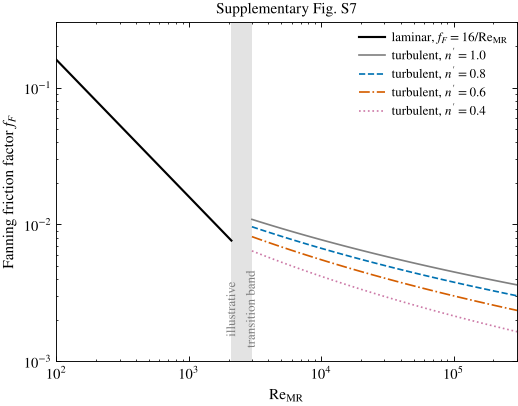

Fig. S7: laminar line, four Dodge-Metzner curves and the band limits agree with data/figure_data/figS7_friction_factor.csv (rtol 1e-8).


In [6]:
fd = pd.read_csv(ROOT / "data" / "figure_data" / "figS7_friction_factor.csv", comment="#")
def stored(series):
    return fd[fd.series == series].sort_values("index")

Re_lam = np.logspace(2, np.log10(2100), 50)
Re_t = np.logspace(np.log10(3000), 5.5, 80)
curves = {}
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.loglog(Re_lam, 16 / Re_lam, color="k", lw=1.4, label=r"laminar, $f_F=16/\mathrm{Re_{MR}}$")
s = stored("laminar, $f_F=16/\\mathrm{Re_{MR}}$")
assert np.allclose(s.x, Re_lam, rtol=1e-8) and np.allclose(s.y, 16 / Re_lam, rtol=1e-8)
for npr, col, ls in zip([1.0, 0.8, 0.6, 0.4], [C["grey"], C["blue"], C["red"], C["purple"]], ["-", "--", "-.", ":"]):
    f = np.array([dodge_metzner(Re, npr) for Re in Re_t])
    curves[npr] = f
    ax.loglog(Re_t, f, color=col, ls=ls, label=f"turbulent, $n'={npr}$")
    s = stored(f"turbulent, $n$′ = {npr}")
    assert np.allclose(s.x, Re_t, rtol=1e-8) and np.allclose(s.y, f, rtol=1e-8), npr
band = stored("illustrative transition band").iloc[0]
assert np.isclose(band.x, 2100) and np.isclose(band.x_end, 3000)
ax.axvspan(2100, 3000, color=C["lightgrey"], alpha=0.5, lw=0)
ax.text(np.sqrt(2100 * 3000), 1.25e-3, "illustrative\ntransition band", rotation=90, ha="center", va="bottom",
        fontsize=8.5, color=C["grey"])
ax.set(xlabel=r"$\mathrm{Re_{MR}}$", ylabel=r"Fanning friction factor $f_F$", xlim=(1e2, 3e5), ylim=(1e-3, 3e-1))
ax.legend(loc="upper right", fontsize=8.5)
ax.set_title("Supplementary Fig. S7", fontsize=10)
plt.show()
print("Fig. S7: laminar line, four Dodge-Metzner curves and the band limits agree with "
      "data/figure_data/figS7_friction_factor.csv (rtol 1e-8).")

**Read the shaded band with care.** It marks where a *Newtonian* pipe flow commonly becomes transitional; it is not a prediction for HB fluids. For yield-stress fluids the onset depends on the yield stress (plug break-up), on shear thinning, on the inlet disturbance and on the material's history, and experiments show broad, intermittent transitions rather than a sharp switch (Supplementary Notes S12 A and S12 C). In design, a flow whose $\mathrm{Re_{MR}}$ falls near this band should be treated as of uncertain regime, and the pressure drop bracketed by both branches.

## 7. Worked example 1 (laminar): a slurry pipeline

Supplementary Note S15 B, Example 1: a slurry with $\sigma_y=5$ Pa, $K=0.5$ Pa s$^{0.7}$, $n=0.7$, $\rho=1200$ kg/m$^3$ is pumped at $Q=10$ L/s through $L=500$ m of 100 mm pipe. The review reports $\sigma_w=20.0$ Pa, $\phi=0.25$, a plug radius of 12.5 mm, $\Delta p=401$ kPa, $U=1.27$ m/s, $n'=0.48$, $K'=2.18$ Pa s$^{0.48}$ and $\mathrm{Re_{MR}}=776$. We reproduce each number.

In [7]:
ty, K, n, rho = 5.0, 0.5, 0.7, 1200.0
Q, L, D = 0.010, 500.0, 0.100
R = D / 2

G = hb_prediction.pressure_gradient(Q, R, ty, K, n)    # solve Eq. (19) for the wall stress (Brent's method)
tw = G * R / 2
U = Q / (np.pi * R**2)
dp = 4 * tw * L / D
npr, Kpr = n_prime(tw, R, ty, K, n), K_prime(tw, R, ty, K, n)
Re = re_mr(rho, U, D, npr, Kpr)
fF = 16 / Re

results = {"sigma_w (Pa)": (tw, 20.0, 1), "phi": (ty / tw, 0.25, 2), "plug radius (mm)": (1000 * R * ty / tw, 12.5, 1),
           "Delta p (kPa)": (dp / 1000, 401, 0), "U (m/s)": (U, 1.27, 2), "n'": (npr, 0.48, 2),
           "K' (Pa s^n')": (Kpr, 2.18, 2), "Re_MR": (Re, 776, 0)}
for name, (value, printed, digits) in results.items():
    print(f"{name:18s} computed {value:10.4f}   printed in Note S15 B: {printed}")
    assert round(value, digits) == printed, name
# the laminar friction factor reproduces the pressure drop: dp = 2 f_F rho U^2 L / D
assert np.isclose(2 * fF * rho * U**2 * L / D, dp, rtol=1e-10)
print("All printed values of Example 1 are reproduced to the digits shown; f_F = 16/Re_MR gives the same pressure drop.")

sigma_w (Pa)       computed    20.0485   printed in Note S15 B: 20.0
phi                computed     0.2494   printed in Note S15 B: 0.25
plug radius (mm)   computed    12.4697   printed in Note S15 B: 12.5
Delta p (kPa)      computed   400.9705   printed in Note S15 B: 401
U (m/s)            computed     1.2732   printed in Note S15 B: 1.27
n'                 computed     0.4798   printed in Note S15 B: 0.48
K' (Pa s^n')       computed     2.1813   printed in Note S15 B: 2.18
Re_MR              computed   776.2633   printed in Note S15 B: 776
All printed values of Example 1 are reproduced to the digits shown; f_F = 16/Re_MR gives the same pressure drop.


Note how far $n'=0.48$ is from $n=0.7$: the yield stress contributes to the local slope, exactly as Sec. 3 predicted for $\sigma_w/\sigma_y=4$.

## 8. Worked example 2 (turbulent): circulating a drilling fluid at a high rate (beyond the article)

**Problem.** The water-based drilling fluid of notebook 05 (Skadsem and Saasen, 2019, as listed in `data/hb_parameter_atlas.csv`: $\sigma_y=4.29$ Pa, $K=0.70$ Pa s$^{0.52}$, $n=0.52$; density **assumed** $\rho=1200$ kg/m$^3$) is circulated at 1500 L/min through 1000 m of smooth pipe with $D=0.10$ m. Estimate the pressure drop and the pumping power.

**Method** (Dodge and Metzner, 1959). The unknown is the wall shear stress $\sigma_w$. For a trial $\sigma_w$:
1. read $n'(\sigma_w)$ and $K'(\sigma_w)$ off the *laminar* HB pipe-flow curve (Sec. 3);
2. compute $\mathrm{Re_{MR}}$ from Eq. (9) with the actual mean velocity $U$;
3. compute $f_F$ from the Dodge–Metzner correlation;
4. require consistency with the definition $f_F=2\sigma_w/(\rho U^2)$.

Step 4 is one equation for $\sigma_w$, solved with Brent's method. (In turbulent flow $8\rho U^2/\sigma_w$ is **not** equal to $\mathrm{Re_{MR}}$; that identity holds only on the laminar branch.)

In [8]:
atlas = pd.read_csv(ROOT / "data" / "hb_parameter_atlas.csv")
row = atlas[atlas.material == "Water-based drilling fluid"].iloc[0]
ty, K, n = float(row.sigma_y_Pa), float(row.K_Pa_s_n), float(row.n)
rho = 1200.0                       # kg/m^3, ASSUMED
D, L = 0.10, 1000.0
R = D / 2

def dodge_metzner_wide(Re, npr):
    """Same correlation with a wider bracket, so that trial values far from the root do not fail."""
    g = lambda ff: 1 / np.sqrt(ff) - (4 / npr**0.75) * np.log10(Re * ff ** (1 - npr / 2)) + 0.4 / npr**1.2
    return brentq(g, 1e-6, 1.0)

def turbulent_state(tw, U):
    npr, Kpr = n_prime(tw, R, ty, K, n), K_prime(tw, R, ty, K, n)
    Re = re_mr(rho, U, D, npr, Kpr)
    return npr, Kpr, Re, dodge_metzner_wide(Re, npr)

def solve_turbulent(Q):
    U = Q / (np.pi * R**2)
    tw_lam = hb_prediction.pressure_gradient(Q, R, ty, K, n) * R / 2      # laminar wall stress: a lower bound
    mismatch = lambda tw: turbulent_state(tw, U)[3] - 2 * tw / (rho * U**2)
    tw = brentq(mismatch, tw_lam * 1.0001, 100 * tw_lam, xtol=1e-10)
    return tw, tw_lam, U

Q = 1500 / 60000                                    # m^3/s
tw, tw_lam, U = solve_turbulent(Q)
npr, Kpr, Re, fF = turbulent_state(tw, U)
dp = 4 * tw * L / D
print(f"mean velocity U = {U:.2f} m/s")
print(f"laminar solution (for comparison): sigma_w = {tw_lam:.2f} Pa, Re_MR = {8 * rho * U**2 / tw_lam:.0f}"
      f"  -> beyond the laminar range, so the laminar answer does not apply")
print(f"turbulent solution: sigma_w = {tw:.2f} Pa, n' = {npr:.3f}, K' = {Kpr:.3f} Pa s^n', Re_MR = {Re:.0f}, f_F = {fF:.5f}")
print(f"pressure drop over {L:.0f} m: {dp / 1e5:.2f} bar  (laminar formula would give {4 * tw_lam * L / D / 1e5:.2f} bar)")
print(f"pumping power Q*dp = {Q * dp / 1000:.1f} kW")
print(f"check: 8 rho U^2/sigma_w = {8 * rho * U**2 / tw:.0f}, not equal to Re_MR = {Re:.0f} in turbulent flow")

mean velocity U = 3.18 m/s
laminar solution (for comparison): sigma_w = 19.22 Pa, Re_MR = 5061  -> beyond the laminar range, so the laminar answer does not apply
turbulent solution: sigma_w = 33.52 Pa, n' = 0.438, K' = 1.639 Pa s^n', Re_MR = 5257, f_F = 0.00551
pressure drop over 1000 m: 13.41 bar  (laminar formula would give 7.69 bar)
pumping power Q*dp = 33.5 kW
check: 8 rho U^2/sigma_w = 2902, not equal to Re_MR = 5257 in turbulent flow


The turbulent wall stress is about 1.7 times the laminar value at the same flow rate, so a laminar calculation would underestimate the pressure drop by about 40 %. The Reynolds number, $\mathrm{Re_{MR}}\approx5300$, is above the illustrative band, and the local index $n'\approx0.44$ lies within the range plotted in Fig. S7.

**The factor-of-four trap.** If the friction factor $f_F$ were mistaken for a Darcy factor and inserted into $\Delta p=f_D\rho U^2L/(2D)$, the pressure drop would be four times too small:

In [9]:
dp_wrong = fF * rho * U**2 * L / (2 * D)          # Fanning factor used in the Darcy formula: WRONG
dp_right = 4 * fF * rho * U**2 * L / (2 * D)      # f_D = 4 f_F
print(f"correct: {dp_right / 1e5:.2f} bar;   Fanning value used as Darcy: {dp_wrong / 1e5:.2f} bar")
assert np.isclose(dp_right, dp)

correct: 13.41 bar;   Fanning value used as Darcy: 3.35 bar


### 8.1 The drilling fluid across the regimes

Finally, we sweep the flow rate and place the drilling fluid on the friction-factor chart: the exact laminar branch (where $\mathrm{Re_{MR}}<2100$) and the Dodge–Metzner branch (where $\mathrm{Re_{MR}}>3000$). Between them the chart is blank on purpose.

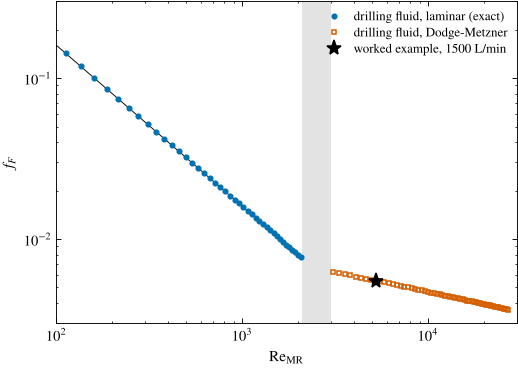

along the turbulent branch n' ranges from 0.39 to 0.50


In [10]:
Q_lam = np.linspace(50, 1100, 60) / 60000
Q_tur = np.linspace(1100, 4000, 60) / 60000
lam = []
for q in Q_lam:
    t = hb_prediction.pressure_gradient(q, R, ty, K, n) * R / 2
    u = q / (np.pi * R**2)
    lam.append((8 * rho * u**2 / t, 2 * t / (rho * u**2)))
lam = np.array(lam)
tur = []
for q in Q_tur:
    t, _, u = solve_turbulent(q)
    npr_q, Kpr_q, Re_q, f_q = turbulent_state(t, u)
    tur.append((Re_q, f_q, npr_q))
tur = np.array(tur)

fig, ax = plt.subplots(figsize=(5.4, 3.8))
Re_line = np.logspace(2, np.log10(2100), 50)
ax.loglog(Re_line, 16 / Re_line, color="k", lw=0.6)
ok = lam[:, 0] < 2100
ax.loglog(lam[ok, 0], lam[ok, 1], "o", ms=3, color=C["blue"], label="drilling fluid, laminar (exact)")
ok = tur[:, 0] > 3000
ax.loglog(tur[ok, 0], tur[ok, 1], "s", ms=3, mfc="none", color=C["red"], label="drilling fluid, Dodge-Metzner")
ax.axvspan(2100, 3000, color=C["lightgrey"], alpha=0.5, lw=0)
ax.plot([Re], [fF], "*", ms=10, color=C["black"], label="worked example, 1500 L/min")
ax.set(xlabel=r"$\mathrm{Re_{MR}}$", ylabel=r"$f_F$", xlim=(1e2, 3e4), ylim=(3e-3, 3e-1))
ax.legend(fontsize=8.5, loc="upper right")
plt.show()
print(f"along the turbulent branch n' ranges from {tur[tur[:, 0] > 3000, 2].min():.2f} to {tur[:, 2].max():.2f}")

The laminar points fall exactly on $16/\mathrm{Re_{MR}}$, as they must. The turbulent points follow a Dodge–Metzner curve whose $n'$ changes slowly with the flow rate because the wall stress changes. Nothing in this framework says where, between the two, the actual flow switches — that has to come from experiments on the fluid of interest or from a dedicated transition criterion, and should be reported as an uncertainty (Supplementary Notes S12 A–C).

## 9. Try it yourself

**Exercise 1 — is the yield stress important in turbulent flow?** For the 1500 L/min example, change $\sigma_y$ by $\pm20$ % and recompute the turbulent pressure drop. Compare with the change at a laminar operating point (400 L/min, notebook 05).

*Hint:* `ty` is a global used by `n_prime`, `K_prime` and `solve_turbulent`; reassign it, recompute, and restore it afterwards.

<details><summary>Solution</summary>

```python
ty0 = ty
for factor in [0.8, 1.0, 1.2]:
    ty = factor * ty0
    t_turb, _, _ = solve_turbulent(1500 / 60000)
    t_lam = hb_prediction.pressure_gradient(400 / 60000, R, ty, K, n) * R / 2
    print(factor, f"turbulent dp = {4 * t_turb * L / D / 1e5:.2f} bar", f"laminar (400 L/min) sigma_w = {t_lam:.2f} Pa")
ty = ty0
# the turbulent pressure drop changes by less than 1 % (slightly downwards, through a smaller n'),
# whereas the laminar wall stress at 400 L/min changes by about +/-8 %
```
</details>

**Exercise 2 — where does the laminar branch end?** Find the flow rate at which the laminar $\mathrm{Re_{MR}}=8\rho U^2/\sigma_w$ reaches 2100 for the drilling fluid, and explain why this is not "the" transition flow rate.

*Hint:* `brentq` on $Q\mapsto\mathrm{Re_{MR}}(Q)-2100$ between 100 and 2000 L/min.

<details><summary>Solution</summary>

```python
def re_lam(q_lpm):
    q = q_lpm / 60000; u = q / (np.pi * R**2)
    t = hb_prediction.pressure_gradient(q, R, ty, K, n) * R / 2
    return 8 * rho * u**2 / t
print(brentq(lambda q: re_lam(q) - 2100, 100, 2000), "L/min")   # about 880 L/min
# 2100 is a Newtonian convention; the actual onset for this fluid depends on its yield stress,
# shear thinning, the inlet disturbance and history (Supplementary Note S12).
```
</details>

**Exercise 3 — wall units.** Supplementary Eq. (S31) defines a reference wall viscosity $\eta_{w,\rm ref}=\sigma_w/[(\sigma_w-\sigma_y)/K]^{1/n}$ and a wall length $\ell_{w,\rm ref}=\eta_{w,\rm ref}/(\rho u_\sigma)$ with $u_\sigma=(\sigma_w/\rho)^{1/2}$. Compute them for the turbulent worked example and express the pipe radius in these wall units.

<details><summary>Solution</summary>

```python
eta_w = tw / ((tw - ty) / K) ** (1 / n)
u_sigma = np.sqrt(tw / rho)
ell_w = eta_w / (rho * u_sigma)
print(eta_w, u_sigma, ell_w, R / ell_w)   # R is about 400 wall units
# The review notes that this is a convention, not the mean instantaneous wall viscosity of a turbulent flow.
```
</details>

## Key points

* $n'=\mathrm{d}\ln\sigma_w/\mathrm{d}\ln(8U/D)$ and $K'=\sigma_w/(8U/D)^{n'}$ are local properties of the laminar pipe-flow curve; for an HB fluid $n'\to0$ near the threshold and $n'\to n$ far above it.
* With these, $\mathrm{Re_{MR}}$ (Eq. (9)) reduces to $8\rho U^2/\sigma_w$ and $f_F=16/\mathrm{Re_{MR}}$ **exactly** in laminar HB flow.
* The Dodge–Metzner correlation gives the turbulent branch, with $n'$ and $K'$ read off the laminar curve at the turbulent wall stress; it is empirical and should be used inside its calibration domain.
* $\Delta p=4\sigma_wL/D$ and $f_D=4f_F$: keep the conventions straight.
* The transition band of Fig. S7 is illustrative only: there is no single critical $\mathrm{Re_{MR}}$ for HB fluids, and near-transition designs should carry the regime uncertainty.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Rabinowitsch, B. (1929). Über die Viskosität und Elastizität von Solen. *Zeitschrift für Physikalische Chemie* **145A**, 1–26. https://doi.org/10.1515/zpch-1929-14502
* Mooney, M. (1931). Explicit formulas for slip and fluidity. *Journal of Rheology* **2**, 210–222. https://doi.org/10.1122/1.2116364
* Metzner, A. B., and Reed, J. C. (1955). Flow of non-Newtonian fluids — correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409
* Dodge, D. W., and Metzner, A. B. (1959). Turbulent flow of non-Newtonian systems. *AIChE Journal* **5**, 189–204. https://doi.org/10.1002/aic.690050214
* Hanks, R. W. (1963). The laminar–turbulent transition for fluids with a yield stress. *AIChE Journal* **9**, 306–309. https://doi.org/10.1002/aic.690090307
* Escudier, M. P., and Presti, F. (1996). Pipe flow of a thixotropic liquid. *Journal of Non-Newtonian Fluid Mechanics* **62**, 291–306. https://doi.org/10.1016/0377-0257(96)01417-6
* Peixinho, J., Nouar, C., Desaubry, C., and Théron, B. (2005). Laminar transitional and turbulent flow of yield stress fluid in a pipe. *Journal of Non-Newtonian Fluid Mechanics* **128**, 172–184. https://doi.org/10.1016/j.jnnfm.2005.03.008
* Güzel, B., Burghelea, T., Frigaard, I. A., and Martinez, D. M. (2009). Observation of laminar–turbulent transition of a yield stress fluid in Hagen–Poiseuille flow. *Journal of Fluid Mechanics* **627**, 97–128. https://doi.org/10.1017/s0022112009005813
* Skadsem, H. J., and Saasen, A. (2019). Concentric cylinder viscometer flows of Herschel–Bulkley fluids. *Applied Rheology* **29**, 173–181. https://doi.org/10.1515/arh-2019-0015
* Charles, A., Peixinho, J., Ribeiro, T., Azimi, S., Rocher, V., Baudez, J.-C., and Bahrani, S. A. (2024). Asymmetry and intermittency in the rheo-inertial transition to turbulence in pipe flow. *Physics of Fluids* **36**, 054120. https://doi.org/10.1063/5.0211807
* Yusufi, B. K., Kapelan, Z., and Mehta, D. (2025). Advances in modeling the flow of Herschel–Bulkley fluids in pipes: A review. *Physics of Fluids* **37**, 021302. https://doi.org/10.1063/5.0252248

### Further reading

* Yusufi, B. K., Kapelan, Z., and Mehta, D. (2024). Rheology-based wall function approach for wall-bounded turbulent flows of Herschel–Bulkley fluids. *Physics of Fluids* **36**, 023112. https://doi.org/10.1063/5.0180663